# GARBAGE CLASSIFICATION — Object Detection EDA
**Independent Google Colab notebook** · No training required.

Investigates extreme differences in BIODEGRADABLE, GLASS, PAPER and PLASTIC across train/valid/test. Includes missing labels, invalid YOLO annotations, duplicate images, image sizes, object counts, class heatmaps, organic test examples, and a final audit report. **Run all cells in order.**

In [ ]:
%pip -q install pandas numpy matplotlib seaborn pillow pyyaml tqdm

In [ ]:
from pathlib import Path

root = Path('/content/drive/MyDrive')

# 1) What's at the top level of MyDrive
print('Top-level folders:')
for p in sorted(root.iterdir()):
    print('  ', p.name)

# 2) Case-insensitive search (up to 3 levels deep) for anything with "garbage" in the name
print('\nMatches for "garbage" (case-insensitive):')
for pattern in ['*', '*/*', '*/*/*']:
    for p in root.glob(pattern):
        if 'garbage' in p.name.lower():
            print('  ', p)

# 3) Any data.yaml files (YOLO-format datasets)
print('\ndata.yaml files found:')
for p in root.glob('**/data.yaml'):
    print('  ', p)

Top-level folders:
   Afnan-Alshehri-CV (1).pdf
   Colab Notebooks
   DS Bootcamp lewagon ,SDA
   DitsN.drawio
   Relationship (1).drawio.png
   Relationship.drawio
   Relationship.drawio.png
   Relationship.jpg
   Untitled Diagram
   Untitled Diagram.drawio
   general.drawio
   waste_to_value
   سيرة ذاتية.pdf
   صورة.jpg
   نموذج بدون عنوان.gform

Matches for "garbage" (case-insensitive):
   /content/drive/MyDrive/Colab Notebooks/Copy of garbage yolo26mssd

data.yaml files found:


## 1 · Connect Google Drive and locate dataset

In [ ]:
import kagglehub, yaml
from pathlib import Path

# 1) Download (public dataset; cached on repeat runs)
dl = Path(kagglehub.dataset_download('viswaprakash1990/garbage-detection'))
yamls = sorted(dl.rglob('data.yaml'))
assert yamls, f'No data.yaml under {dl}'
SRC = yamls[0].parent
print('Source:', SRC, '->', sorted(p.name for p in SRC.iterdir()))

# 2) Read class names from the original file (no retyping)
orig = yaml.safe_load(open(SRC / 'data.yaml'))
names = orig['names']
print('Classes:', names)

# 3) Clean folder with symlinks (no copying, no space in path)
DATASET_ROOT = Path('/content/garbage')
DATASET_ROOT.mkdir(exist_ok=True)
for split in ['train', 'valid', 'test']:
    link = DATASET_ROOT / split
    if link.is_symlink() or link.exists():
        link.unlink()
    link.symlink_to(SRC / split, target_is_directory=True)

# 4) Corrected data.yaml with absolute root
cfg = {'path': str(DATASET_ROOT),
       'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
       'nc': len(names), 'names': names}
yaml.safe_dump(cfg, open(DATASET_ROOT / 'data.yaml', 'w'), sort_keys=False)

# 5) Sanity check
for split in ['train', 'valid', 'test']:
    n = len(list((DATASET_ROOT / split / 'images').glob('*')))
    print(f'{split}: {n} images')
YAML_FILES = [DATASET_ROOT / 'data.yaml']

100%|██████████| 191M/191M [00:09<00:00, 20.3MB/s]

Extracting files...


Source: /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1/GARBAGE CLASSIFICATION -> ['data.yaml', 'test', 'train', 'valid']
Classes: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']
train: 7324 images
valid: 2098 images
test: 1042 images


In [ ]:
DATA_YAML = DATASET_ROOT / 'data.yaml'
print(DATA_YAML, DATA_YAML.exists())

/content/garbage/data.yaml True


## 2 · Resolve class names and split folders

In [ ]:
cfg = yaml.safe_load(DATA_YAML.read_text())
raw_names = cfg.get('names', {})
NAMES = {int(k): str(v) for k, v in raw_names.items()} if isinstance(raw_names, dict) else dict(enumerate(raw_names))
print('Class mapping (do not assume organic class ID):')
for k,v in NAMES.items(): print(f'  {k}: {v}')

# Locate actual image directories, prioritizing train/valid/test folders under dataset root.
def find_split_dir(split):
    aliases = {'train':['train'], 'val':['valid','val','validation'], 'test':['test']}[split]
    for a in aliases:
        d = DATASET_ROOT / a / 'images'
        if d.is_dir(): return d
    spec = cfg.get(split, cfg.get('val') if split=='val' else None)
    if spec is None: return None
    if isinstance(spec, list): spec=spec[0]
    base = Path(cfg.get('path', DATASET_ROOT))
    options = [Path(str(spec)), DATA_YAML.parent / str(spec), DATASET_ROOT / str(spec), base / str(spec)]
    for opt in options:
        if opt.is_dir(): return opt
    return None

SPLITS = {s:find_split_dir(s) for s in ['train','val','test']}
print('Split folders:', SPLITS)
if any(v is None for v in SPLITS.values()):
    raise FileNotFoundError('Missing split directory. Inspect YAML and DATASET_ROOT above.')


Class mapping (do not assume organic class ID):
  0: BIODEGRADABLE
  1: CARDBOARD
  2: GLASS
  3: METAL
  4: PAPER
  5: PLASTIC
Split folders: {'train': PosixPath('/content/garbage/train/images'), 'val': PosixPath('/content/garbage/valid/images'), 'test': PosixPath('/content/garbage/test/images')}


## 3 · Scan every image and annotation (including missing/invalid labels)

In [ ]:
OUTPUT = Path('/content/drive/MyDrive/garbage_outputs')
OUTPUT.mkdir(parents=True, exist_ok=True)
print(OUTPUT, OUTPUT.exists())

/content/drive/MyDrive/garbage_outputs True


In [ ]:
IMAGE_EXTS={'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
images_rows=[]; boxes_rows=[]; issues=[]

def label_for(img, img_dir):
    # Standard YOLO dataset: split/images/foo.jpg -> split/labels/foo.txt
    try: relative=img.relative_to(img_dir)
    except ValueError: relative=Path(img.name)
    if img_dir.name == 'images':
        return img_dir.parent/'labels'/relative.with_suffix('.txt')
    return img_dir.parent/'labels'/relative.with_suffix('.txt')

for split, img_dir in SPLITS.items():
    image_paths=sorted(x for x in img_dir.rglob('*') if x.is_file() and x.suffix.lower() in IMAGE_EXTS)
    print(f'Scanning {split}: {len(image_paths)} images')
    for img in tqdm(image_paths, desc=split):
        label=label_for(img,img_dir)
        row={'split':split,'image':str(img),'label':str(label),'filename':img.name,'label_exists':label.exists(), 'image_ok':False, 'width':np.nan,'height':np.nan,'n_objects':0,'n_valid_objects':0,'invalid_rows':0}
        try:
            with Image.open(img) as im:
                row['width'],row['height']=im.size
                im.verify()
            row['image_ok']=True
        except Exception as e: issues.append({'split':split,'image':str(img),'issue':'unreadable_image','details':str(e)})
        if not label.exists():
            issues.append({'split':split,'image':str(img),'issue':'missing_label_file','details':''})
        else:
            try: lines=[x.strip() for x in label.read_text().splitlines() if x.strip()]
            except Exception as e:
                lines=[]; issues.append({'split':split,'image':str(img),'issue':'unreadable_label','details':str(e)})
            row['n_objects']=len(lines)
            for lineno,line in enumerate(lines,1):
                tokens=line.split()
                try:
                    if len(tokens)!=5: raise ValueError(f'expected 5 tokens, got {len(tokens)}')
                    cid_float=float(tokens[0]); cid=int(cid_float)
                    if cid_float != cid or cid not in NAMES: raise ValueError(f'unknown class ID {tokens[0]}')
                    x,y,w,h=map(float,tokens[1:])
                    if not all(np.isfinite([x,y,w,h])): raise ValueError('nonfinite coordinate')
                    if not (0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1): raise ValueError('out-of-range YOLO coordinate')
                    if x-w/2 < -1e-5 or x+w/2 > 1+1e-5 or y-h/2 < -1e-5 or y+h/2 > 1+1e-5: raise ValueError('bounding box extends outside image')
                    boxes_rows.append({'split':split,'image':str(img),'class_id':cid,'class_name':NAMES[cid], 'x':x,'y':y,'w':w,'h':h,'area':w*h,'width_px':w*row['width'],'height_px':h*row['height']})
                    row['n_valid_objects']+=1
                except Exception as e:
                    row['invalid_rows']+=1
                    issues.append({'split':split,'image':str(img),'issue':'invalid_annotation','details':f'line {lineno}: {e}'})
        images_rows.append(row)

images_df=pd.DataFrame(images_rows)
boxes_df=pd.DataFrame(boxes_rows, columns=['split','image','class_id','class_name','x','y','w','h','area','width_px','height_px'])
issues_df=pd.DataFrame(issues, columns=['split','image','issue','details'])
for name,df in [('images',images_df),('boxes',boxes_df),('issues',issues_df)]:
    df.to_csv(OUTPUT/f'{name}_audit.csv',index=False)
print('Scanned images:',len(images_df),'Valid boxes:',len(boxes_df),'Issues:',len(issues_df))
display(issues_df.groupby(['split','issue']).size().unstack(fill_value=0) if len(issues_df) else pd.DataFrame({'status':['No issues found']}))


Scanning train: 7324 images


train:   0%|          | 0/7324 [00:00<?, ?it/s]

Scanning val: 2098 images


val:   0%|          | 0/2098 [00:00<?, ?it/s]

Scanning test: 1042 images


test:   0%|          | 0/1042 [00:00<?, ?it/s]

Scanned images: 10464 Valid boxes: 74073 Issues: 17


issue,invalid_annotation
split,
test,1
train,10
val,6


In [ ]:
pd.set_option('display.max_colwidth', None)
print('Total issues:', len(issues_df))
display(issues_df.groupby(['split', 'issue']).size().rename('count').to_frame())
display(issues_df.sort_values(['split', 'image']).reset_index(drop=True))

Total issues: 17


,,count
split,issue,
test,invalid_annotation,1
train,invalid_annotation,10
val,invalid_annotation,6


,split,image,issue,details
0,test,/content/garbage/test/images/paper1430_jpg.rf.4da0e71eab5e1a13f510f439c7d7fd28.jpg,invalid_annotation,line 9: out-of-range YOLO coordinate
1,train,/content/garbage/train/images/biodegradable1465_jpg.rf.6554b314de4df3aed0117f0283e9df7f.jpg,invalid_annotation,line 54: out-of-range YOLO coordinate
2,train,/content/garbage/train/images/biodegradable1740_jpg.rf.5f00e1157464c17341765a596a148298.jpg,invalid_annotation,line 64: out-of-range YOLO coordinate
3,train,/content/garbage/train/images/biodegradable1998_jpeg.rf.17921ee65cee3e00f10a24d639dff35b.jpg,invalid_annotation,line 261: out-of-range YOLO coordinate
4,train,/content/garbage/train/images/biodegradable2012_jpeg.rf.f157a4549b3da5de53b7d15eb8ed051d.jpg,invalid_annotation,line 26: out-of-range YOLO coordinate
5,train,/content/garbage/train/images/biodegradable366_jpg.rf.09e6cd29dee38feb3b4df80653e5fb0f.jpg,invalid_annotation,line 18: out-of-range YOLO coordinate
6,train,/content/garbage/train/images/biodegradable419_jpg.rf.3cb6ccbe84af9a0d1a083252e479def4.jpg,invalid_annotation,line 32: out-of-range YOLO coordinate
7,train,/content/garbage/train/images/biodegradable421_jpg.rf.0d8bc76989848c2d9173e3c49c133867.jpg,invalid_annotation,line 94: out-of-range YOLO coordinate
8,train,/content/garbage/train/images/cardboard895_jpg.rf.9fe0d5e9a4d71705fa33323a01dcc534.jpg,invalid_annotation,line 3: out-of-range YOLO coordinate
9,train,/content/garbage/train/images/paper1805_jpeg.rf.3cbe8e415d51c085ff0165a12cea5880.jpg,invalid_annotation,line 1: out-of-range YOLO coordinate


In [ ]:
import re

bad = []
for _, r in issues_df.iterrows():
    img = Path(r['image'])
    lbl = img.parent.parent / 'labels' / (img.stem + '.txt')
    line_no = int(re.search(r'line (\d+)', r['details']).group(1))
    lines = lbl.read_text().splitlines()
    parts = lines[line_no - 1].split()
    c = int(parts[0]); x, y, w, h = map(float, parts[1:5])
    vals = {'x': x, 'y': y, 'w': w, 'h': h}
    worst = max(max(v - 1, 0 - v, 0) for v in vals.values())
    bad.append({'split': r['split'], 'image': img.name[:35], 'line': line_no,
                'boxes_in_img': len(lines), 'class': NAMES.get(c, f'?{c}'),
                **vals, 'overshoot': round(worst, 6)})

bad_df = pd.DataFrame(bad).sort_values('overshoot', ascending=False)
display(bad_df)
print('Invalid boxes per class:'); display(bad_df['class'].value_counts())
print('Max overshoot:', bad_df['overshoot'].max())

,split,image,line,boxes_in_img,class,x,y,w,h,overshoot
0,train,biodegradable1465_jpg.rf.6554b314de,54,64,BIODEGRADABLE,0.412260,0.895433,0.012019,0.000000,0
1,train,biodegradable1740_jpg.rf.5f00e11574,64,99,BIODEGRADABLE,0.256010,0.561298,0.000000,0.043269,0
2,train,biodegradable1998_jpeg.rf.17921ee65,261,321,BIODEGRADABLE,0.478365,0.475962,0.062500,0.000000,0
3,train,biodegradable2012_jpeg.rf.f157a4549,26,44,BIODEGRADABLE,0.224760,0.640625,0.004808,0.000000,0
4,train,biodegradable366_jpg.rf.09e6cd29dee,18,92,BIODEGRADABLE,0.441106,0.391827,0.048077,0.000000,0
5,train,biodegradable419_jpg.rf.3cb6ccbe84a,32,67,BIODEGRADABLE,0.481971,0.155048,0.004808,0.000000,0
6,train,biodegradable421_jpg.rf.0d8bc769898,94,228,BIODEGRADABLE,0.836538,0.574519,0.000000,0.007212,0
7,train,cardboard895_jpg.rf.9fe0d5e9a4d7170,3,18,CARDBOARD,0.165865,0.209135,0.000000,0.004808,0
8,train,paper1805_jpeg.rf.3cbe8e415d51c085f,1,3,PAPER,0.306490,0.149038,0.000000,0.004808,0
9,train,paper787_jpg.rf.a776cf355b31868a4cf,1,2,PAPER,0.949519,0.854567,0.004808,0.000000,0


Invalid boxes per class:


,count
class,
BIODEGRADABLE,12
PAPER,3
CARDBOARD,2


Max overshoot: 0


split,train,valid,test,Total
class,,,,
BIODEGRADABLE,7,5,0,12
CARDBOARD,1,1,0,2
GLASS,0,0,0,0
METAL,0,0,0,0
PAPER,2,0,1,3
PLASTIC,0,0,0,0
Total,10,6,1,17


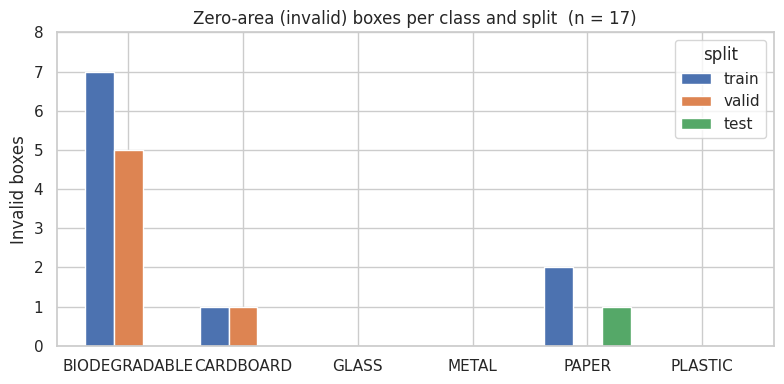

In [ ]:
import matplotlib.pyplot as plt

order = [NAMES[k] for k in sorted(NAMES)]
tab = (pd.crosstab(bad_df['class'], bad_df['split'].replace({'val': 'valid'}))
       .reindex(index=order, columns=['train', 'valid', 'test'], fill_value=0))
tab['Total'] = tab.sum(axis=1)
tab.loc['Total'] = tab.sum()
display(tab)

ax = tab.drop(index='Total', columns='Total').plot(kind='bar', figsize=(8, 4), width=0.75)
ax.set_title('Zero-area (invalid) boxes per class and split  (n = 17)')
ax.set_xlabel(''); ax.set_ylabel('Invalid boxes')
ax.set_yticks(range(0, int(tab.drop(index='Total', columns='Total').values.max()) + 2))
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUTPUT / 'invalid_boxes_per_class.png', dpi=150)
plt.show()

In [ ]:
from collections import defaultdict

rows = []
for split in ['train', 'valid', 'test']:
    img_dir = DATASET_ROOT / split / 'images'
    lbl_dir = DATASET_ROOT / split / 'labels'
    for img in img_dir.iterdir():
        lbl = lbl_dir / (img.stem + '.txt')
        classes_in_img = set()
        if lbl.exists():
            for line in lbl.read_text().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue
                try:
                    c = int(parts[0]); x, y, w, h = map(float, parts[1:])
                except ValueError:
                    continue
                if c in NAMES and all(0 <= v <= 1 for v in (x, y, w, h)) and w > 0 and h > 0:
                    rows.append({'split': split, 'image': img.name, 'class': NAMES[c]})
                    classes_in_img.add(c)
        if not classes_in_img:
            rows.append({'split': split, 'image': img.name, 'class': '(no valid box)'})

cls_df = pd.DataFrame(rows)
order = [NAMES[k] for k in sorted(NAMES)] + ['(no valid box)']

# Images per class (an image with 2 classes counts once in each)
img_per_class = (cls_df.drop_duplicates(['split', 'image', 'class'])
                 .pivot_table(index='class', columns='split', values='image', aggfunc='count', fill_value=0)
                 .reindex(order, fill_value=0)[['train', 'valid', 'test']])
img_per_class['total'] = img_per_class.sum(axis=1)
print('Images per class:')
display(img_per_class)

# Boxes per class (for cross-checking against the audit)
box_per_class = (cls_df[cls_df['class'] != '(no valid box)']
                 .pivot_table(index='class', columns='split', values='image', aggfunc='count', fill_value=0)
                 .reindex(order[:-1], fill_value=0)[['train', 'valid', 'test']])
box_per_class['total'] = box_per_class.sum(axis=1)
print('Boxes per class:')
display(box_per_class)
print('Total valid boxes here:', int(box_per_class['total'].sum()), '| audit said:', len(boxes_df))

Images per class:


split,train,valid,test,total
class,,,,
BIODEGRADABLE,1603,676,8,2287
CARDBOARD,1053,438,11,1502
GLASS,1879,805,0,2684
METAL,1328,398,172,1898
PAPER,1238,15,515,1768
PLASTIC,1019,91,354,1464
(no valid box),0,0,0,0


Boxes per class:


split,train,valid,test,total
class,,,,
BIODEGRADABLE,31714,13632,49,45395
CARDBOARD,3385,1291,20,4696
GLASS,5429,2380,0,7809
METAL,3948,1360,533,5841
PAPER,2979,33,1375,4387
PLASTIC,4146,214,1585,5945


Total valid boxes here: 74073 | audit said: 74073


## 4 · Split sizes, class distributions and imbalance

Images by split:


,images,unreadable,missing_labels,empty_or_invalid
split,,,,
train,7324,0,0,0
val,2098,0,0,0
test,1042,0,0,0


OBJECTS (bounding boxes) per class:


split,train,val,test
class_name,,,
BIODEGRADABLE,31714,13632,49
CARDBOARD,3385,1291,20
GLASS,5429,2380,0
METAL,3948,1360,533
PAPER,2979,33,1375
PLASTIC,4146,214,1585


IMAGES containing each class (image can appear in multiple rows):


split,train,val,test
class_name,,,
BIODEGRADABLE,1603,676,8
CARDBOARD,1053,438,11
GLASS,1879,805,0
METAL,1328,398,172
PAPER,1238,15,515
PLASTIC,1019,91,354


Class percentage by split:


split,train,val,test
class_name,,,
BIODEGRADABLE,61.46,72.09,1.38
CARDBOARD,6.56,6.83,0.56
GLASS,10.52,12.59,0.00
METAL,7.65,7.19,14.96
PAPER,5.77,0.17,38.60
PLASTIC,8.03,1.13,44.50


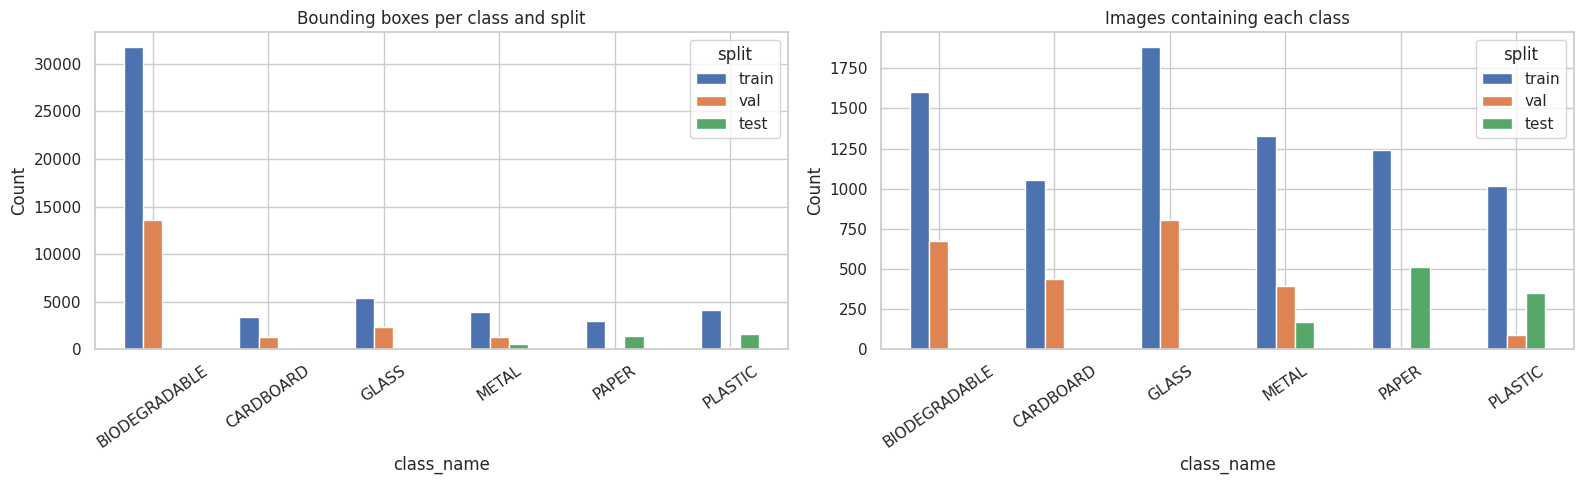

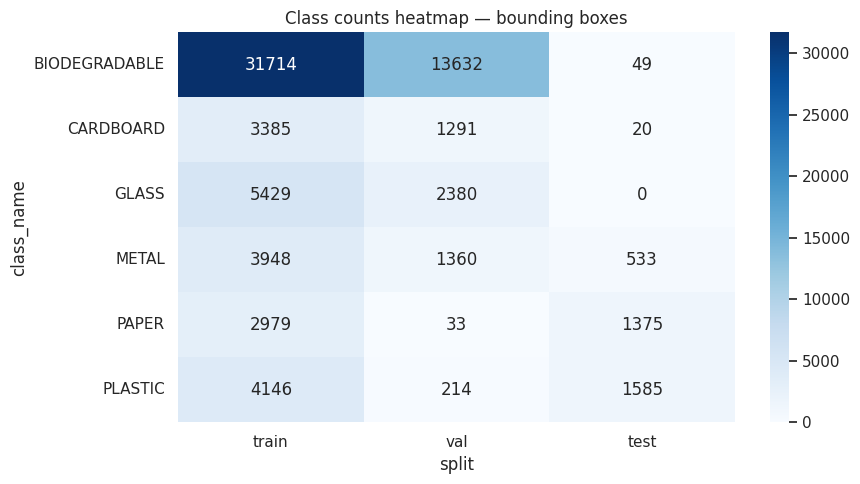

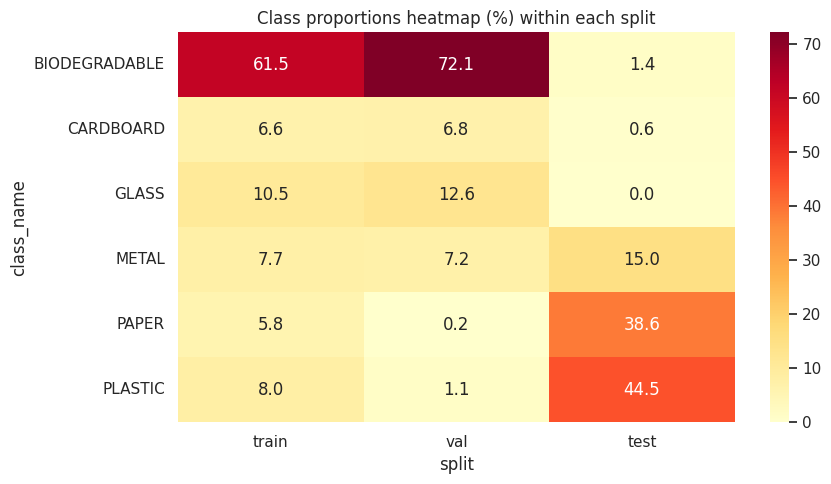

In [ ]:
split_order=['train','val','test']
counts=boxes_df.groupby(['class_name','split']).size().unstack(fill_value=0).reindex(columns=split_order,fill_value=0).reindex(NAMES.values(),fill_value=0)
image_counts=(boxes_df.groupby(['class_name','split'])['image'].nunique().unstack(fill_value=0).reindex(columns=split_order,fill_value=0).reindex(NAMES.values(),fill_value=0))
print('Images by split:'); display(images_df.groupby('split').agg(images=('image','size'), unreadable=('image_ok',lambda s:(~s).sum()), missing_labels=('label_exists',lambda s:(~s).sum()), empty_or_invalid=('n_valid_objects',lambda s:(s==0).sum())).reindex(split_order))
print('OBJECTS (bounding boxes) per class:'); display(counts)
print('IMAGES containing each class (image can appear in multiple rows):'); display(image_counts)
print('Class percentage by split:'); display((counts.div(counts.sum(axis=0),axis=1)*100).round(2))
counts.to_csv(OUTPUT/'class_box_distribution.csv')
image_counts.to_csv(OUTPUT/'class_image_distribution.csv')
fig,axes=plt.subplots(1,2,figsize=(16,5))
counts.plot(kind='bar',ax=axes[0],title='Bounding boxes per class and split')
image_counts.plot(kind='bar',ax=axes[1],title='Images containing each class')
for ax in axes: ax.set_ylabel('Count');ax.tick_params(axis='x',rotation=35)
plt.tight_layout();plt.savefig(OUTPUT/'class_distributions.png',dpi=160);plt.show()

plt.figure(figsize=(9,5))
sns.heatmap(counts,annot=True,fmt='d',cmap='Blues')
plt.title('Class counts heatmap — bounding boxes');plt.tight_layout();plt.savefig(OUTPUT/'class_heatmap.png',dpi=160);plt.show()
plt.figure(figsize=(9,5))
sns.heatmap(counts.div(counts.sum(axis=0).replace(0,np.nan),axis=1)*100,annot=True,fmt='.1f',cmap='YlOrRd')
plt.title('Class proportions heatmap (%) within each split');plt.tight_layout();plt.savefig(OUTPUT/'class_percent_heatmap.png',dpi=160);plt.show()


## 5 · Image size, object count, and bounding box size

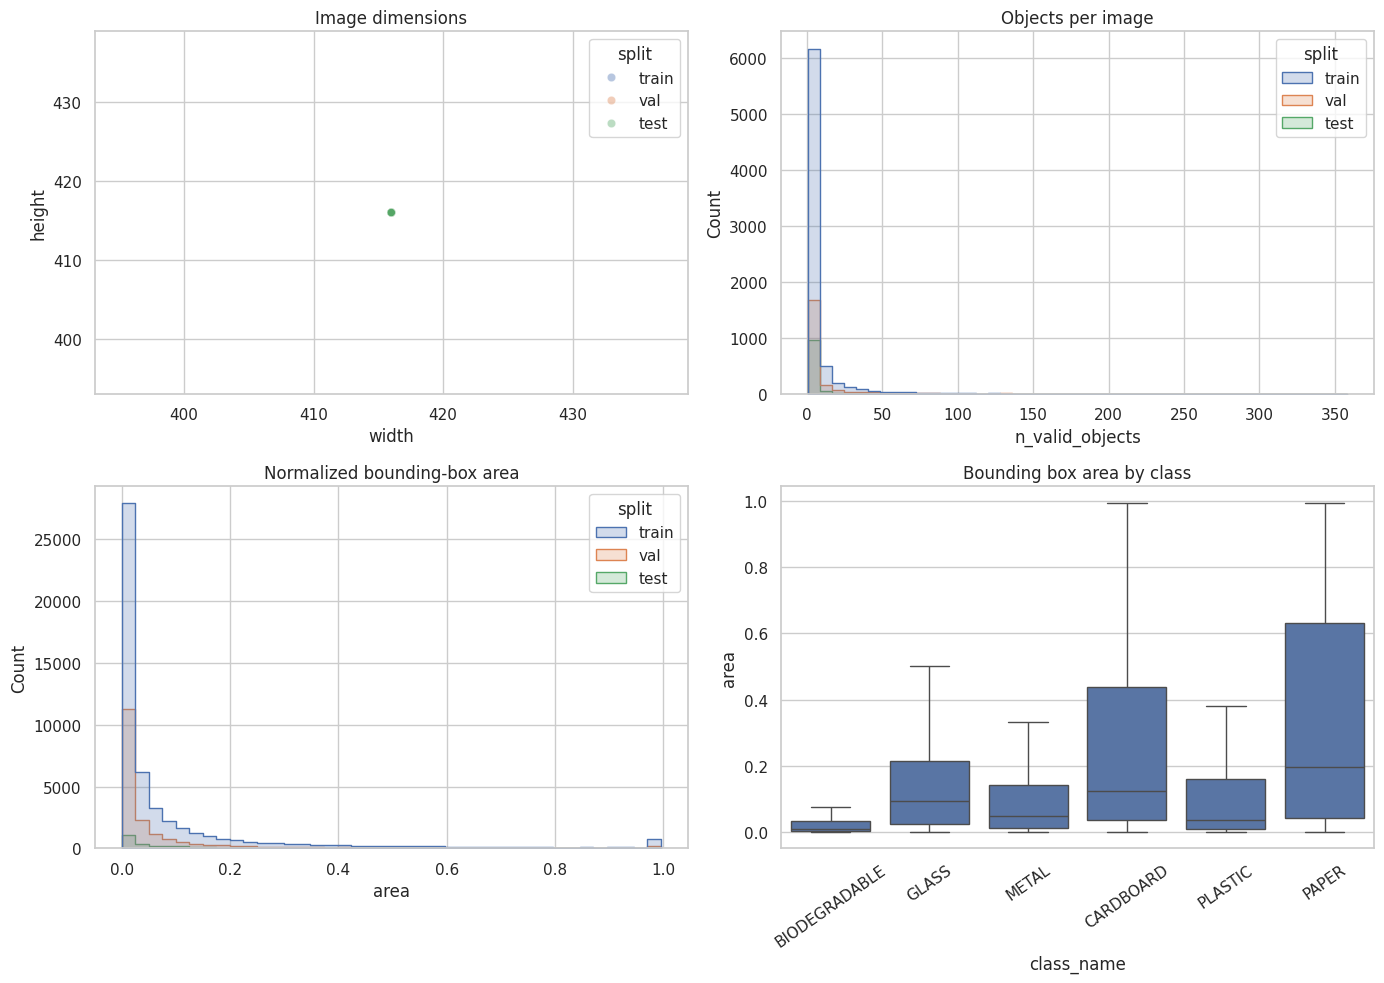

Image dimensions summary:


width                                                 height         \
        count   mean  std    min    25%    50%    75%    max   count   mean   
split                                                                         
test   1042.0  416.0  0.0  416.0  416.0  416.0  416.0  416.0  1042.0  416.0   
train  7324.0  416.0  0.0  416.0  416.0  416.0  416.0  416.0  7324.0  416.0   
val    2098.0  416.0  0.0  416.0  416.0  416.0  416.0  416.0  2098.0  416.0   

       ...               n_valid_objects                                        
       ...    75%    max           count mean   std  min  25%  50%  75%    max  
split  ...                                                                      
test   ...  416.0  416.0          1042.0  3.4   8.4  1.0  1.0  1.0  3.0  119.0  
train  ...  416.0  416.0          7324.0  7.0  19.3  1.0  1.0  2.0  5.0  358.0  
val    ...  416.0  416.0          2098.0  9.0  21.7  1.0  1.0  2.0  6.0  311.0  

[3 rows x 24 columns]

In [ ]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
sns.scatterplot(data=images_df,x='width',y='height',hue='split',alpha=.4,ax=axes[0,0]);axes[0,0].set_title('Image dimensions')
sns.histplot(data=images_df,x='n_valid_objects',hue='split',bins=45,element='step',ax=axes[0,1]);axes[0,1].set_title('Objects per image')
if not boxes_df.empty:
    sns.histplot(data=boxes_df,x='area',hue='split',bins=40,element='step',ax=axes[1,0]);axes[1,0].set_title('Normalized bounding-box area')
    sns.boxplot(data=boxes_df,x='class_name',y='area',ax=axes[1,1],showfliers=False);axes[1,1].tick_params(axis='x',rotation=35);axes[1,1].set_title('Bounding box area by class')
plt.tight_layout();plt.savefig(OUTPUT/'image_and_box_distributions.png',dpi=160);plt.show()
print('Image dimensions summary:');display(images_df.groupby('split')[['width','height','n_valid_objects']].describe().round(1))


1. Dataset size and splits

10,464 images: train 7,324, valid 2,098, test 1,042.
All images are a uniform 416×416 px, so there are no size outliers.

2. Annotation quality

17 invalid annotations were found, one per image, in 17 images (train 10, valid 6, test.

Action: the 17 lines were removed rather than clipped, since a zero-area box carries no recoverable information.
The removal did not leave any image empty, because every image still has at least 1 valid box.
Why it matters: the invalid PAPER box in test could never be matched by any model, so it would have counted as a missed detection and unfairly lowered PAPER recall and mAP.

3. split

Test scenes are noticeably sparser than validation scenes (mean 3.4 vs 9.0 objects per image; 75th percentile 3 vs 6).
The splits are therefore not identically distributed, which partly explains gaps between validation and test results.

## 6 · Organic bounding box location heatmap and co-occurrence

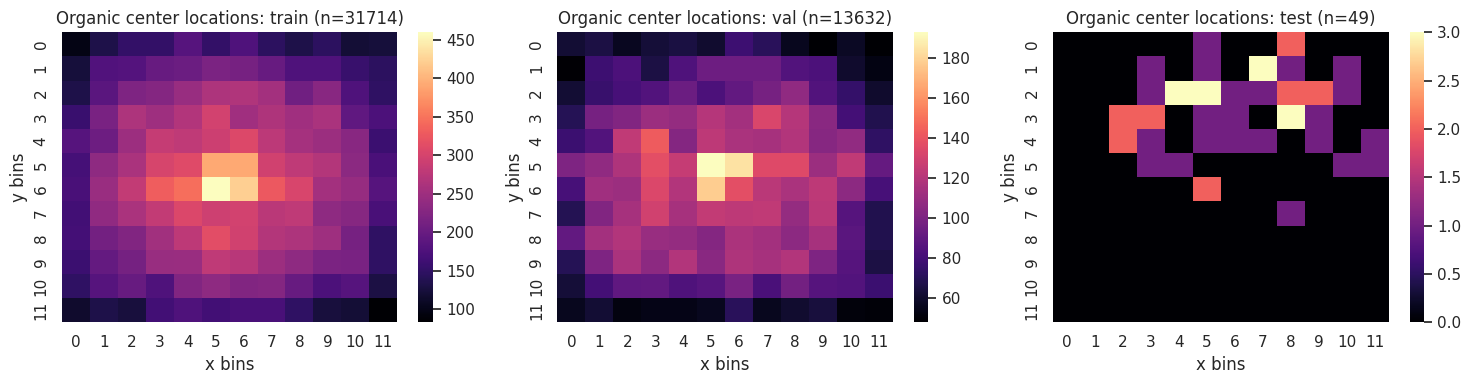

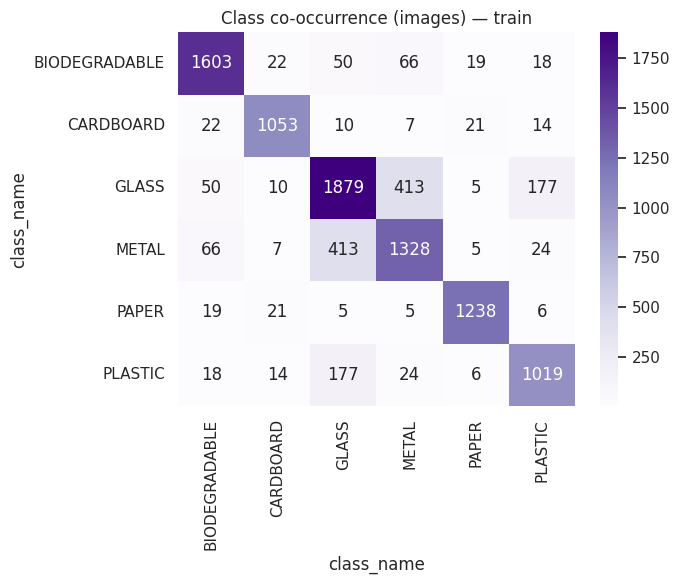

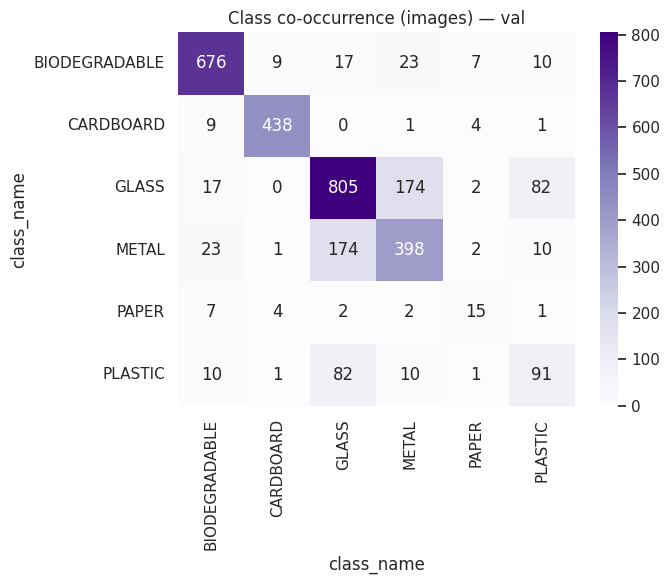

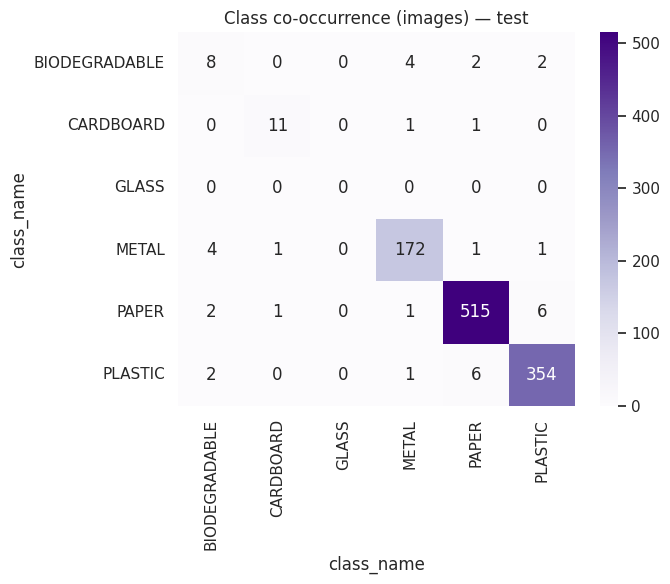

In [ ]:
organic_ids=[i for i,name in NAMES.items() if 'BIODEGRAD' in name.upper() or 'ORGANIC' in name.upper()]
organic_id=organic_ids[0] if organic_ids else None
if organic_id is None: print('No organic class found. Check class names.')
else:
    ob=boxes_df[boxes_df.class_id==organic_id]
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for ax,split in zip(axes,split_order):
        b=ob[ob.split==split]
        if len(b):
            h,xe,ye=np.histogram2d(b.y,b.x,bins=12,range=[[0,1],[0,1]])
            sns.heatmap(h,ax=ax,cmap='magma',cbar=True)
        ax.set_title(f'Organic center locations: {split} (n={len(b)})');ax.set_xlabel('x bins');ax.set_ylabel('y bins')
    plt.tight_layout();plt.savefig(OUTPUT/'organic_location_heatmap.png',dpi=160);plt.show()

presence=boxes_df.groupby(['split','image','class_name']).size().unstack(fill_value=0).gt(0)
if len(presence):
    for split in split_order:
        sub=presence.loc[split] if split in presence.index.get_level_values(0) else pd.DataFrame(columns=presence.columns)
        mat=sub.astype(int).T.dot(sub.astype(int))
        plt.figure(figsize=(7,6));sns.heatmap(mat,annot=True,fmt='d',cmap='Purples');plt.title(f'Class co-occurrence (images) — {split}')
        plt.tight_layout();plt.savefig(OUTPUT/f'cooccurrence_{split}.png',dpi=160);plt.show()


## 7 · Exact duplicates across splits (potential leakage)

In [ ]:
# SHA-256 on file bytes; can take several minutes on Google Drive.
sha_rows=[]
for row in tqdm(images_df.itertuples(index=False),total=len(images_df),desc='Hashing images'):
    try:
        h=hashlib.sha256()
        with open(row.image,'rb') as f:
            for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
        sha_rows.append({'split':row.split,'image':row.image,'sha256':h.hexdigest()})
    except Exception as e: issues.append({'split':row.split,'image':row.image,'issue':'hash_error','details':str(e)})
sha_df=pd.DataFrame(sha_rows)
sha_df.to_csv(OUTPUT/'image_hashes.csv',index=False)
dups=sha_df.groupby('sha256').filter(lambda g:g['split'].nunique()>1).sort_values('sha256') if len(sha_df) else sha_df
dups.to_csv(OUTPUT/'cross_split_exact_duplicates.csv',index=False)
print('Exact duplicate image files appearing in multiple splits:',dups.sha256.nunique() if len(dups) else 0)
display(dups.head(30))
print('Note: exact hashing does not detect resized or near-duplicate images.')


Hashing images:   0%|          | 0/10464 [00:00<?, ?it/s]

Exact duplicate image files appearing in multiple splits: 0


,split,image,sha256


Note: exact hashing does not detect resized or near-duplicate images.


## 8 · Inspect all organic TEST images with ground-truth boxes

Organic TEST images: 8; annotated organic objects: 49


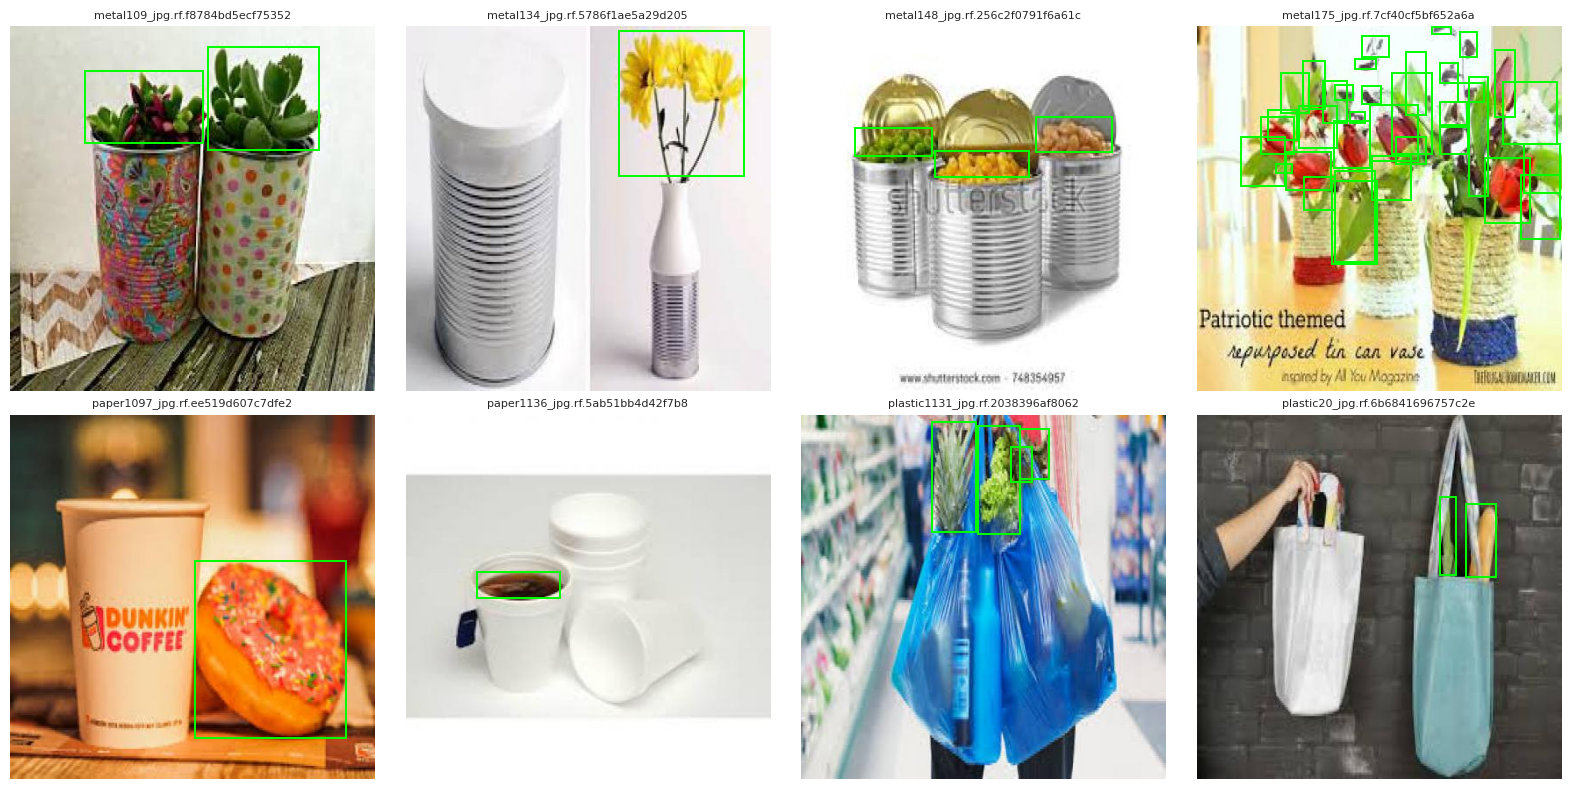

In [ ]:
if organic_id is not None:
    organic_test=boxes_df[(boxes_df.split=='test')&(boxes_df.class_id==organic_id)]
    paths=organic_test.image.drop_duplicates().tolist()
    print(f'Organic TEST images: {len(paths)}; annotated organic objects: {len(organic_test)}')
    if not paths: print('No organic test examples available.')
    for start in range(0,len(paths),8):
        subset=paths[start:start+8]
        fig,axes=plt.subplots((len(subset)+3)//4,4,figsize=(16,4*((len(subset)+3)//4)))
        axes=np.array(axes).reshape(-1)
        for ax,img_path in zip(axes,subset):
            with Image.open(img_path) as im: im=ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(im)
            for b in organic_test[organic_test.image==img_path].itertuples():
                x0=(b.x-b.w/2)*im.width; y0=(b.y-b.h/2)*im.height
                ax.add_patch(plt.Rectangle((x0,y0),b.w*im.width,b.h*im.height,fill=False,edgecolor='lime',linewidth=1.4))
            ax.set_title(Path(img_path).name[:32],fontsize=8);ax.axis('off')
        for ax in axes[len(subset):]:ax.axis('off')
        plt.tight_layout();plt.savefig(OUTPUT/f'organic_test_examples_{start//8+1}.png',dpi=150);plt.show()


##Inspect all classes TEST images with ground-truth boxes


BIODEGRADABLE TEST images: 8; annotated BIODEGRADABLE objects: 49


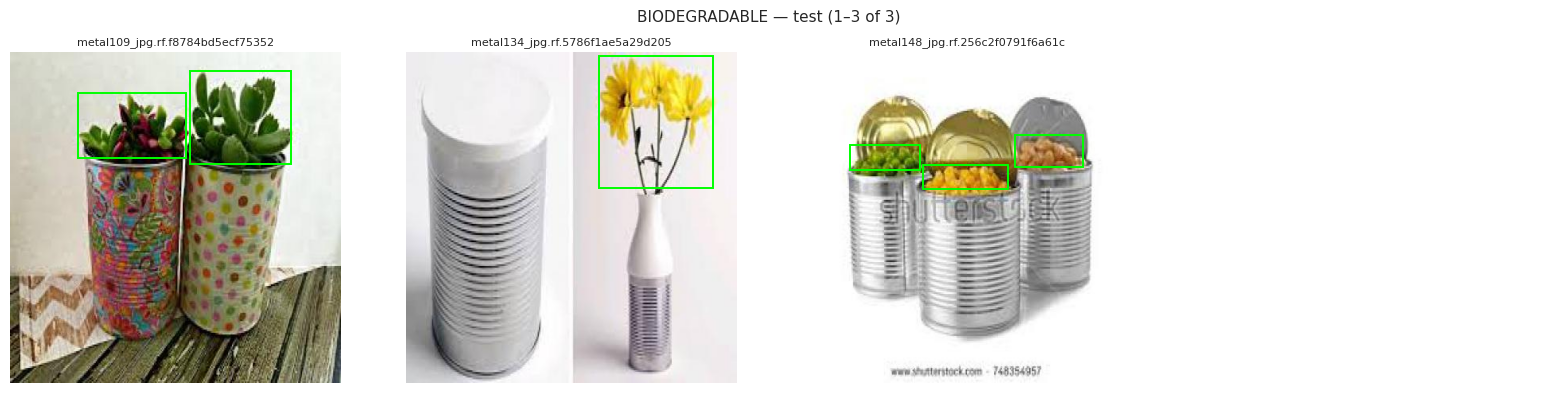


CARDBOARD TEST images: 11; annotated CARDBOARD objects: 20


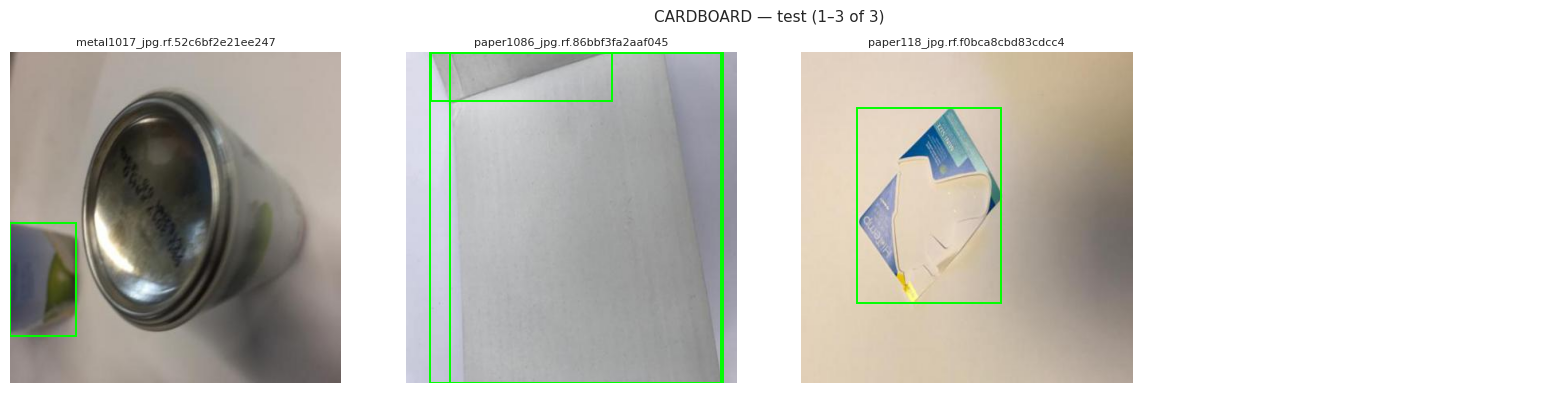


GLASS TEST images: 0; annotated GLASS objects: 0
No GLASS test examples available.

METAL TEST images: 172; annotated METAL objects: 533


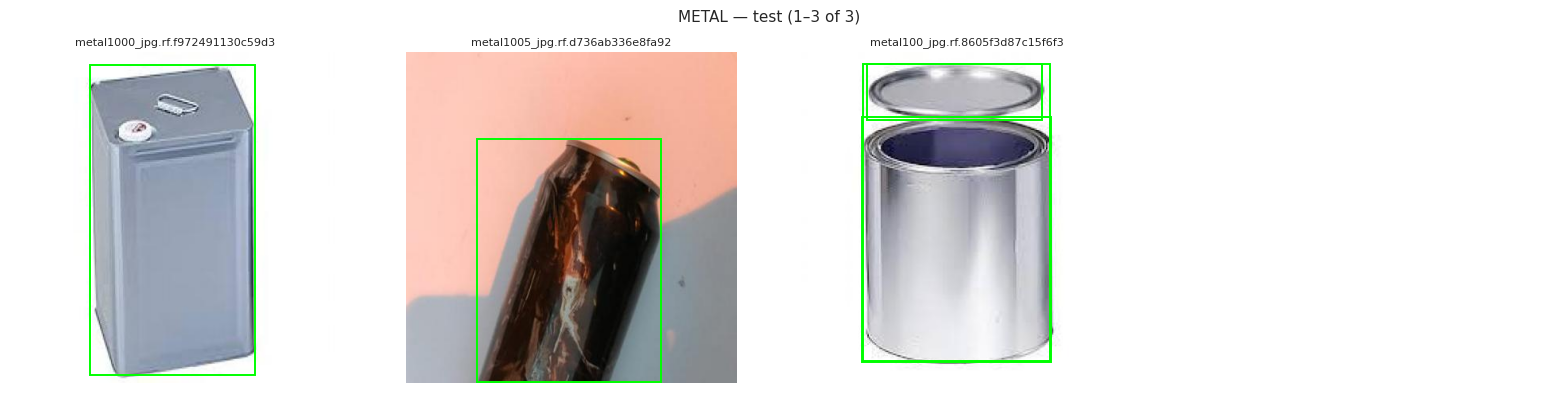


PAPER TEST images: 515; annotated PAPER objects: 1375


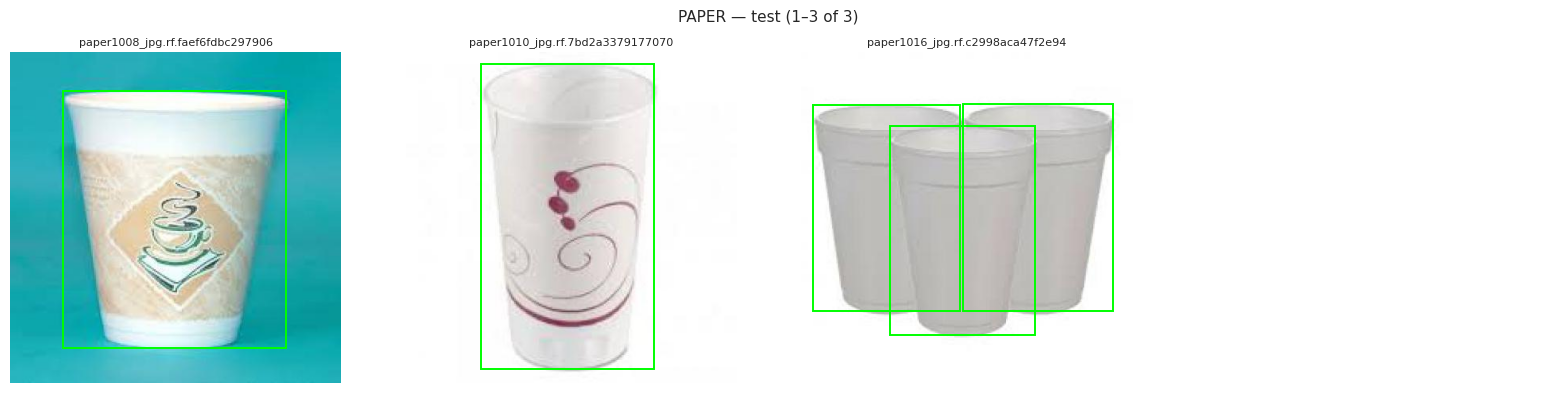


PLASTIC TEST images: 354; annotated PLASTIC objects: 1585


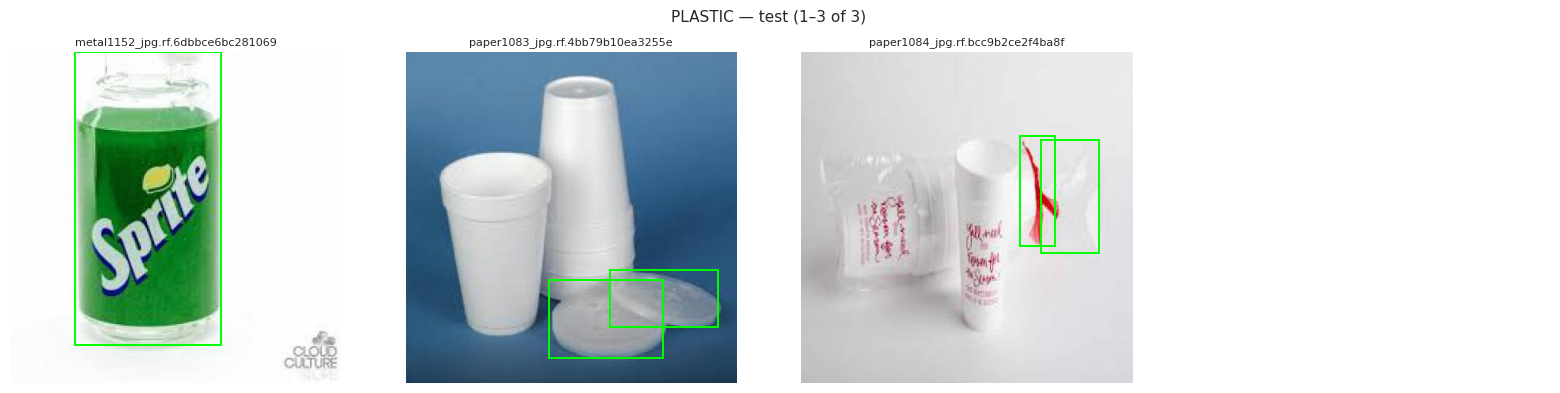

In [ ]:
SPLIT = 'test'
MAX_PER_CLASS = 3  # None = all images (same as original); set e.g. 8 to show only the first 8 per class

for cid in sorted(NAMES):
    cname = NAMES[cid]
    cls_boxes = boxes_df[(boxes_df.split == SPLIT) & (boxes_df.class_id == cid)]
    paths = cls_boxes.image.drop_duplicates().tolist()
    print(f'\n{cname} {SPLIT.upper()} images: {len(paths)}; annotated {cname} objects: {len(cls_boxes)}')
    if not paths:
        print(f'No {cname} {SPLIT} examples available.')
        continue
    if MAX_PER_CLASS:
        paths = paths[:MAX_PER_CLASS]
    for start in range(0, len(paths), 8):
        subset = paths[start:start + 8]
        fig, axes = plt.subplots((len(subset) + 3) // 4, 4, figsize=(16, 4 * ((len(subset) + 3) // 4)))
        axes = np.array(axes).reshape(-1)
        for ax, img_path in zip(axes, subset):
            with Image.open(img_path) as im: im = ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(im)
            for b in cls_boxes[cls_boxes.image == img_path].itertuples():
                x0 = (b.x - b.w / 2) * im.width; y0 = (b.y - b.h / 2) * im.height
                ax.add_patch(plt.Rectangle((x0, y0), b.w * im.width, b.h * im.height, fill=False, edgecolor='lime', linewidth=1.4))
            ax.set_title(Path(img_path).name[:32], fontsize=8); ax.axis('off')
        for ax in axes[len(subset):]: ax.axis('off')
        fig.suptitle(f'{cname} — {SPLIT} ({start + 1}–{start + len(subset)} of {len(paths)})', fontsize=11)
        plt.tight_layout()
        plt.savefig(OUTPUT / f'{cname.lower()}_{SPLIT}_examples_{start // 8 + 1}.png', dpi=150)
        plt.show()

## 9 · Final audit summary and research-relevant warnings

In [ ]:
lines=['='*70,'FINAL DATASET EDA SUMMARY','='*70,f'Dataset: {DATASET_ROOT}',f'Class mapping: {NAMES}','']
for split in split_order:
    im=images_df[images_df.split==split];b=boxes_df[boxes_df.split==split]
    lines += [f'[{split.upper()}] images={len(im):,}, valid_boxes={len(b):,}, missing_label_files={(~im.label_exists).sum():,}, empty_or_no_valid_boxes={(im.n_valid_objects==0).sum():,}, invalid_annotation_rows={im.invalid_rows.sum():,}']
    for cid,name in NAMES.items():
        sub=b[b.class_id==cid]
        lines.append(f'  {name}: boxes={len(sub):,}, images={sub.image.nunique():,}, share={(100*len(sub)/len(b)) if len(b) else 0:.2f}%')
    lines.append('')
lines.append(f'Exact cross-split duplicate files: {dups.sha256.nunique() if len(dups) else 0}')
if organic_id is not None:
    v=counts.loc[NAMES[organic_id],'val']; t=counts.loc[NAMES[organic_id],'test']
    lines.append(f'ORGANIC validation/test object counts: {v:,} / {t:,} (ratio={v/t:.1f}x)' if t else 'ORGANIC has zero TEST objects!')
for cid,name in NAMES.items():
    if counts.loc[name,'test']==0:lines.append(f'WARNING: {name} has ZERO annotated objects in TEST; its test AP cannot be estimated.')
lines += ['', 'IMPORTANT: This notebook audits dataset distributions and label structure; it cannot prove why a model failed.', 'Do not re-split and evaluate an already-trained model on previously seen training images.', 'Missing label files can mean intentional background images OR an annotation problem; review manually.', 'Image-level class counts and box-level counts are different; both are reported.', '='*70]
report='\n'.join(lines)
print(report)
(OUTPUT/'FINAL_EDA_SUMMARY.txt').write_text(report)
print('\nSaved CSVs, charts, examples and final report to:',OUTPUT)


FINAL DATASET EDA SUMMARY
Dataset: /content/garbage
Class mapping: {0: 'BIODEGRADABLE', 1: 'CARDBOARD', 2: 'GLASS', 3: 'METAL', 4: 'PAPER', 5: 'PLASTIC'}

[TRAIN] images=7,324, valid_boxes=51,601, missing_label_files=0, empty_or_no_valid_boxes=0, invalid_annotation_rows=10
  BIODEGRADABLE: boxes=31,714, images=1,603, share=61.46%
  CARDBOARD: boxes=3,385, images=1,053, share=6.56%
  GLASS: boxes=5,429, images=1,879, share=10.52%
  METAL: boxes=3,948, images=1,328, share=7.65%
  PAPER: boxes=2,979, images=1,238, share=5.77%
  PLASTIC: boxes=4,146, images=1,019, share=8.03%

[VAL] images=2,098, valid_boxes=18,910, missing_label_files=0, empty_or_no_valid_boxes=0, invalid_annotation_rows=6
  BIODEGRADABLE: boxes=13,632, images=676, share=72.09%
  CARDBOARD: boxes=1,291, images=438, share=6.83%
  GLASS: boxes=2,380, images=805, share=12.59%
  METAL: boxes=1,360, images=398, share=7.19%
  PAPER: boxes=33, images=15, share=0.17%
  PLASTIC: boxes=214, images=91, share=1.13%

[TEST] images=1,0